In [34]:
# For working with data
import pandas as pd
import numpy as np

# For visualization
import seaborn as sns
import matplotlib.pyplot as plt

# For machine learning modeling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.impute import SimpleImputer

In [35]:
filepath = "../data/raw/train.csv"
raw = pd.read_csv(filepath)

raw.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Customer Status,Last Due Date,Last Payment Date,Churn
0,160831,34,Male,NaN,26,none,17.0,Basic,Quarterly,890.21,30.0,active,06-21,07-08,0
1,354435,30,Male,36.0,22,NaN,15.0,Basic,Annual,954.37,30.0,active,06-10,06-25,0
2,444576,23,Male,44.0,14,none,NaN,Premium,Annual,674.00,21.0,inactive,06-27,07-21,1
3,130847,24,Male,39.0,21,2,14.0,Standard,Quarterly,775.00,18.0,active,06-30,07-14,0
4,108121,26,Male,NaN,26,1,5.0,Basic,Quarterly,679.45,NaN,active,06-29,07-04,0


In [36]:
raw.describe()

,CustomerID,Age,Tenure,Usage Frequency,Payment Delay,Total Spend,Last Interaction,Churn
count,303124.000000,303124.000000,241103.000000,303124.000000,214800.000000,303124.000000,240574.000000,303124.000000
mean,252365.776715,38.444178,31.530657,15.954088,10.258073,667.087312,14.051415,0.299999
std,145860.674838,11.669331,17.206895,8.536377,6.564950,223.225242,8.526133,0.458258
min,1.000000,18.000000,1.000000,1.000000,0.000000,100.000000,1.000000,0.000000
25%,125964.750000,29.000000,17.000000,9.000000,5.000000,540.190000,7.000000,0.000000
50%,252101.500000,39.000000,32.000000,16.000000,10.000000,693.835000,13.000000,0.000000
75%,378554.250000,47.000000,46.000000,23.000000,15.000000,846.532500,21.000000,1.000000
max,505205.000000,65.000000,60.000000,30.000000,30.000000,1000.000000,30.000000,1.000000


## Deal with missing Values

In [37]:
raw.isna().sum()

CustomerID               0
Age                      0
Gender                   0
Tenure               62021
Usage Frequency          0
Support Calls        62420
Payment Delay        88324
Subscription Type        0
Contract Length          0
Total Spend              0
Last Interaction     62550
Customer Status          0
Last Due Date            0
Last Payment Date        0
Churn                    0
dtype: int64

In [38]:
# One hot encoding Categorical values

raw['Subscription Type'] = raw['Subscription Type'].replace({
    'Basic': 0,
    'Standard': 1,
    'Premium': 2
    })

raw['Contract Length'] = raw['Contract Length'].replace({
    'Monthly': 0,
    'Quarterly': 1,
    'Annual': 2
    })

raw['Customer Status'] = raw['Customer Status'].replace({
    'active': 1,
    'inactive': 0
    })

raw['Gender'] = raw['Gender'].replace({
    'Male': 1,
    'Female': 0
    })

raw['Support Calls'] = pd.to_numeric(raw['Support Calls'].replace('none', 0))



In [39]:
# Convert date columns to datetime format
raw['Last Due Date'] = pd.to_datetime(raw['Last Due Date'], format="%m-%d")
raw['Last Payment Date'] = pd.to_datetime(raw['Last Payment Date'], format="%m-%d")


# Fill in missing Payment Delay values by subtracting Last Payment Date with Last Due Date
raw['Payment Delay'] = (raw['Last Payment Date'] - raw['Last Due Date']).dt.days

### I will use a simple imputer to fill in the rest of the missing values with medians of the column

In [40]:
#Impute missing values using 3-NN
impute_cols = ['Tenure', 'Usage Frequency', 'Support Calls', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']


imputer = SimpleImputer(strategy='median')
imputed_values = imputer.fit_transform(raw[impute_cols])

raw[impute_cols] = imputed_values

In [41]:
raw.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Customer Status      0
Last Due Date        0
Last Payment Date    0
Churn                0
dtype: int64

### Save clean dataset

In [42]:
clean_filepath = '../data/processed/train_clean.csv'
raw.to_csv(clean_filepath)
df = raw.copy()

# Some EDA

From this correlation we see that Support Calls, Payment Delays, and Total Spend have the most correlation with churning, so we can focus on those columns. 
We also can see that Customer Status is a leak and should not be passed into the models.

In [43]:
# Get a series with each column correlated to church
corr_with_churn = df.corr()["Churn"]

# Filter to get columns that have a correlation of 0.3 or bigger (negative or positive)
corr_with_churn[abs(corr_with_churn) > 0.3]

Support Calls      0.465354
Payment Delay      0.329147
Total Spend       -0.372350
Customer Status   -1.000000
Churn              1.000000
Name: Churn, dtype: float64

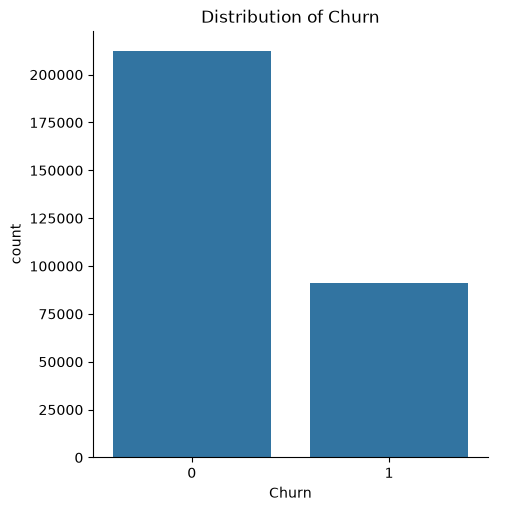

In [77]:
sns.catplot(data=df, x="Churn", kind='count')

plt.title("Distribution of Churn")
plt.show()

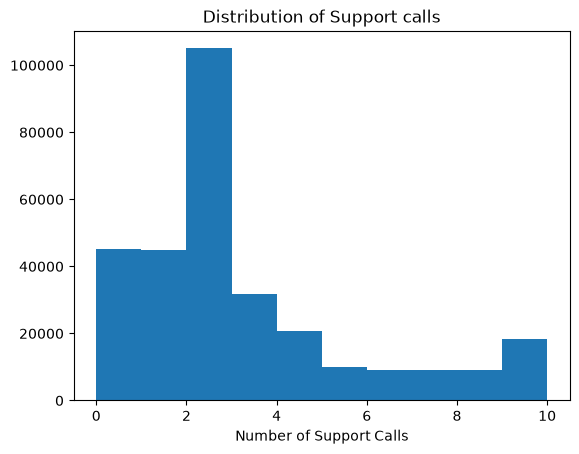

In [75]:
df["Support Calls"].hist()

plt.title("Distribution of Support calls")
plt.xlabel("Number of Support Calls")
plt.grid(False)

plt.show()

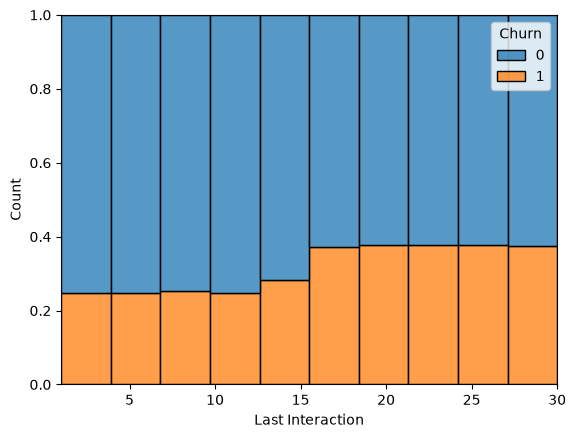

In [62]:
sns.histplot(data=df, x="Last Interaction", hue="Churn", bins=10, multiple="fill")

plt.show()

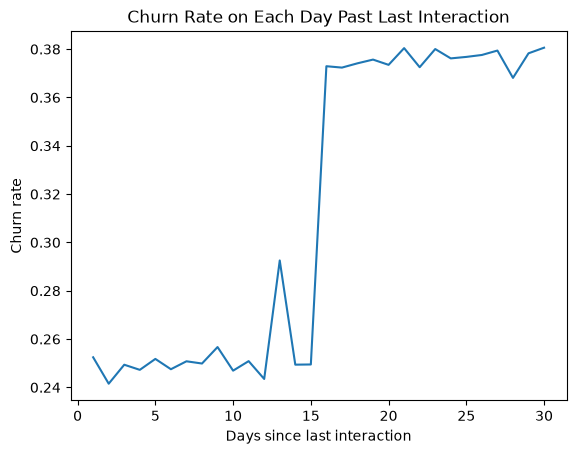

In [46]:
df.groupby("Last Interaction")["Churn"].mean().plot()

plt.title("Churn Rate on Each Day Past Last Interaction")

plt.xlabel("Days since last interaction")
plt.ylabel("Churn rate")

plt.show()